<a href="https://colab.research.google.com/github/davidmarinich1-source/tp-finanzas-computacionales/blob/main/TP_HomeBias.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Carteras óptimas según la fortaleza del dólar
**Finanzas Computacionales 2026 · Trabajo Práctico Integrador**

Armamos carteras de acciones de los 11 sectores de la economía, optimizadas para **tres perfiles de riesgo** y **dos escenarios del dólar** (fuerte y débil), con un tope de **8% por acción** y **25% por sector**. Las comparamos contra la cartera óptima que **no tiene en cuenta el dólar**, con las métricas de riesgo del TP.

**Objetivo:** ver si mirar el dólar mejora la cartera, y en qué acciones y sectores conviene invertir según el perfil y el dólar.

### Cómo correrlo
1. `Entorno de ejecución → Ejecutar todas` (o `Ctrl + F9`).
2. Con `CONFIG["descargar"] = False` (lo normal) usa los datos guardados en el repositorio: no depende de Yahoo Finance y tarda poco.
3. Para actualizar los datos, poner `CONFIG["descargar"] = True` (tarda varios minutos) y seguir los pasos del `README.md`.

### Índice
0. Configuración
1. Universo de acciones
2. Datos de mercado (clase `DatosMercado`)
3. Resumen del universo
4. Señal del dólar (clase `SenalDolar`)
5. Primera mirada: retornos por sector según el dólar
6. Indicadores anticipatorios: tasa a 2 años y M2 (clase `IndicadoresMacro`)
7. Pronóstico del dólar: índice compuesto y validación (clase `PronosticoDolar`)
8. *(próximamente)* Escenarios · Estimación de μ y Σ · Optimizador y carteras · Recomendación de hoy · Backtest y métricas · Stress test · Conclusiones

## 0. Configuración
Todo lo que se puede cambiar está en `CONFIG`. El resto del código **no tiene fechas ni números escritos a mano**: si cambiamos algo acá y hacemos "Ejecutar todas", todo el análisis se recalcula.

Algunos parámetros se usan en secciones que todavía no están armadas (lo indica el comentario).

In [20]:
CONFIG = {
    # ---------------- Datos (secciones 1 y 2) ----------------
    "descargar": False,              # False: usa los datos guardados en el repositorio (presentación)
                                     # True: baja todo de Wikipedia y Yahoo Finance (varios minutos)
    "fecha_inicio": "2015-01-01",
    "fecha_fin": None,               # None = hasta hoy (solo se usa si descargar=True)
    "tolerancia_inicio_dias": 31,    # una acción entra si tiene precios desde (inicio + 31 días)
    "max_faltantes": 0.02,           # se descarta si le falta precio en más del 2% de los días
    "referencias": ["SPY", "ACWI"],  # S&P 500 y mercado mundial (para comparar)

    # ---------------- Señal del dólar (sección 4) ----------------
    "ticker_dolar": "DX-Y.NYB",      # índice del dólar (DXY) en Yahoo Finance
    "ventana_dolar": 200,            # días del promedio móvil

    # ---------------- Indicadores anticipatorios (sección 6) ----------------
    "descargar_indicadores": False,  # True: vuelve a bajar los indicadores de FRED (tarda segundos)
    "indicadores": {"tasa_2a": "DGS2", "m2": "M2SL"},   # nombre: código en FRED
    "atrasos": {"tasa_2a": 0, "m2": 1},  # meses de atraso con que se publica cada dato
    "ventana_indicadores": 3,        # meses para medir el cambio de cada indicador
    "medicion": {"tasa_2a": "puntos", "m2": "porcentaje"},   # cómo se mide el cambio de cada uno

    # ---------------- Pronóstico del dólar (sección 7) ----------------
    "signos": {"tasa_2a": 1, "m2": -1},   # teoría: tasa que sube -> dólar fuerte (+); M2 que crece -> dólar débil (−)
    "horizontes": [1, 3, 6],         # meses hacia adelante para validar el pronóstico
    "ventanas_sensibilidad": [1, 3, 6],   # ventanas alternativas para el análisis de sensibilidad

    # ---------------- Estimación y backtest (próximas secciones) ----------------
    "corte": "2022-12-31",           # hasta acá se estiman las carteras; después se prueban
    "rf": 0.04,                      # tasa libre de riesgo anual (Clase 8)

    # ---------------- Optimización (próximas secciones) ----------------
    "tope_accion": 0.08,             # máximo 8% por acción
    "tope_sector": 0.25,             # máximo 25% por sector
    "peso_minimo": 0.01,             # pesos menores a 1% se eliminan y se reescala
    "lambdas": {"Conservador": 50, "Moderado": 10, "Agresivo": 3},  # aversión al riesgo (calibrados: vol. ~11%, ~14% y ~20%)
    "recalcular": False,             # False: usa las carteras ya calculadas y guardadas

    # ---------------- Repositorio y reproducibilidad ----------------
    "url_repo": "https://raw.githubusercontent.com/davidmarinich1-source/tp-finanzas-computacionales/main/",
    "carpeta_datos": "data",
    "semilla": 42,                   # Monte Carlo siempre da los mismos números
}

In [21]:
import io
import os
import sys
import json
import time
import subprocess
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.max_rows", 60)
plt.rcParams["figure.dpi"] = 110

rng = np.random.default_rng(CONFIG["semilla"])   # generador aleatorio con semilla fija
print("Librerías cargadas. pandas", pd.__version__, "| numpy", np.__version__)

Librerías cargadas. pandas 2.2.3 | numpy 2.4.6


## 1. Universo de acciones
**Criterio (sin límite de cantidad de acciones):**
- **Todas las acciones del S&P 500.** La lista y el sector de cada una salen de Wikipedia.
- **Más ADR de empresas de otros países**, de todos los sectores. Un ADR cotiza en EE.UU. y en dólares, así que **todo queda en la misma moneda** sin hacer conversiones: el precio en dólares del ADR ya incluye cómo se movió la moneda de su país.
- Se quedan solo las acciones con precios desde enero de 2015 y sin huecos importantes (sección 2).

**Limitación a mencionar (sesgo de supervivencia):** usamos las empresas que están **hoy** en el S&P 500. Las que salieron del índice en estos años (por quiebra o mal desempeño) no aparecen, y eso puede hacer que el pasado se vea un poco mejor de lo que fue.

Los sectores usan la clasificación GICS (la misma del S&P 500), traducida al castellano.

In [22]:
# Traducción de los 11 sectores GICS (como vienen en Wikipedia) al castellano
SECTORES_ES = {
    "Information Technology": "Tecnología",
    "Financials": "Financiero",
    "Health Care": "Salud",
    "Energy": "Energía",
    "Consumer Staples": "Consumo básico",
    "Consumer Discretionary": "Consumo discrecional",
    "Industrials": "Industria",
    "Materials": "Materiales",
    "Communication Services": "Comunicación",
    "Utilities": "Servicios públicos",
    "Real Estate": "Inmobiliario",
}

# ADR y acciones extranjeras que cotizan en EE.UU. en dólares: {sector: [(ticker, empresa, país), ...]}
# Si alguna no tiene datos suficientes, la sección 2 la descarta sola y avisa por qué.
ADRS = {
    "Tecnología": [
        ("TSM", "Taiwan Semiconductor", "Taiwán"), ("ASML", "ASML Holding", "Países Bajos"),
        ("SAP", "SAP", "Alemania"), ("INFY", "Infosys", "India"), ("WIT", "Wipro", "India"),
        ("UMC", "United Microelectronics", "Taiwán"), ("ASX", "ASE Technology", "Taiwán"),
        ("STM", "STMicroelectronics", "Suiza"), ("ERIC", "Ericsson", "Suecia"),
        ("NOK", "Nokia", "Finlandia"), ("CHKP", "Check Point Software", "Israel"),
        ("NICE", "NICE", "Israel"), ("LOGI", "Logitech", "Suiza"), ("GLOB", "Globant", "Argentina"),
    ],
    "Financiero": [
        ("HSBC", "HSBC", "Reino Unido"), ("BCS", "Barclays", "Reino Unido"), ("LYG", "Lloyds", "Reino Unido"),
        ("DB", "Deutsche Bank", "Alemania"), ("UBS", "UBS", "Suiza"), ("ING", "ING", "Países Bajos"),
        ("SAN", "Banco Santander", "España"), ("BBVA", "BBVA", "España"),
        ("MUFG", "Mitsubishi UFJ", "Japón"), ("SMFG", "Sumitomo Mitsui", "Japón"), ("MFG", "Mizuho", "Japón"),
        ("HDB", "HDFC Bank", "India"), ("IBN", "ICICI Bank", "India"),
        ("ITUB", "Itaú Unibanco", "Brasil"), ("BBD", "Bradesco", "Brasil"), ("BAP", "Credicorp", "Perú"),
        ("KB", "KB Financial", "Corea del Sur"), ("SHG", "Shinhan Financial", "Corea del Sur"),
        ("RY", "Royal Bank of Canada", "Canadá"), ("TD", "Toronto-Dominion Bank", "Canadá"),
        ("BNS", "Scotiabank", "Canadá"), ("BMO", "Bank of Montreal", "Canadá"), ("CM", "CIBC", "Canadá"),
        ("MFC", "Manulife", "Canadá"), ("SLF", "Sun Life", "Canadá"),
        ("GGAL", "Grupo Financiero Galicia", "Argentina"), ("BMA", "Banco Macro", "Argentina"),
        ("BBAR", "BBVA Argentina", "Argentina"),
    ],
    "Salud": [
        ("NVO", "Novo Nordisk", "Dinamarca"), ("AZN", "AstraZeneca", "Reino Unido"),
        ("NVS", "Novartis", "Suiza"), ("SNY", "Sanofi", "Francia"), ("GSK", "GSK", "Reino Unido"),
        ("TEVA", "Teva", "Israel"), ("PHG", "Philips", "Países Bajos"), ("SNN", "Smith & Nephew", "Reino Unido"),
    ],
    "Energía": [
        ("BP", "BP", "Reino Unido"), ("SHEL", "Shell", "Reino Unido"), ("TTE", "TotalEnergies", "Francia"),
        ("EQNR", "Equinor", "Noruega"), ("E", "Eni", "Italia"), ("PBR", "Petrobras", "Brasil"),
        ("YPF", "YPF", "Argentina"), ("TGS", "Transportadora Gas del Sur", "Argentina"),
        ("EC", "Ecopetrol", "Colombia"), ("SU", "Suncor", "Canadá"), ("CNQ", "Canadian Natural", "Canadá"),
        ("ENB", "Enbridge", "Canadá"), ("TRP", "TC Energy", "Canadá"), ("IMO", "Imperial Oil", "Canadá"),
        ("CVE", "Cenovus", "Canadá"),
    ],
    "Consumo básico": [
        ("UL", "Unilever", "Reino Unido"), ("BUD", "AB InBev", "Bélgica"), ("DEO", "Diageo", "Reino Unido"),
        ("BTI", "British American Tobacco", "Reino Unido"), ("NSRGY", "Nestlé", "Suiza"),
        ("FMX", "FEMSA", "México"), ("KOF", "Coca-Cola FEMSA", "México"), ("ABEV", "Ambev", "Brasil"),
        ("CCU", "CCU", "Chile"), ("CRESY", "Cresud", "Argentina"),
    ],
    "Consumo discrecional": [
        ("TM", "Toyota", "Japón"), ("HMC", "Honda", "Japón"), ("SONY", "Sony", "Japón"),
        ("BABA", "Alibaba", "China"), ("JD", "JD.com", "China"), ("TCOM", "Trip.com", "China"),
        ("LVMUY", "LVMH", "Francia"), ("MELI", "MercadoLibre", "Argentina"),
    ],
    "Industria": [
        ("CNI", "Canadian National Railway", "Canadá"), ("CP", "Canadian Pacific Kansas City", "Canadá"),
        ("CAE", "CAE", "Canadá"), ("TRI", "Thomson Reuters", "Canadá"), ("RELX", "RELX", "Reino Unido"),
        ("SIEGY", "Siemens", "Alemania"), ("ERJ", "Embraer", "Brasil"),
        ("PAC", "Grupo Aeroportuario del Pacífico", "México"), ("ASR", "Grupo Aeroportuario del Sureste", "México"),
        ("OMAB", "Grupo Aeroportuario Centro Norte", "México"),
    ],
    "Materiales": [
        ("BHP", "BHP", "Australia"), ("RIO", "Rio Tinto", "Reino Unido"), ("VALE", "Vale", "Brasil"),
        ("TX", "Ternium", "Argentina"), ("SQM", "SQM", "Chile"), ("CRH", "CRH", "Irlanda"),
        ("MT", "ArcelorMittal", "Luxemburgo"), ("PKX", "POSCO", "Corea del Sur"), ("GGB", "Gerdau", "Brasil"),
        ("SID", "CSN", "Brasil"), ("GFI", "Gold Fields", "Sudáfrica"), ("SCCO", "Southern Copper", "Perú"),
        ("BAK", "Braskem", "Brasil"),
    ],
    "Comunicación": [
        ("VOD", "Vodafone", "Reino Unido"), ("AMX", "América Móvil", "México"), ("BIDU", "Baidu", "China"),
        ("NTES", "NetEase", "China"), ("TEF", "Telefónica", "España"), ("CHT", "Chunghwa Telecom", "Taiwán"),
        ("TLK", "Telkom Indonesia", "Indonesia"), ("SKM", "SK Telecom", "Corea del Sur"),
        ("TU", "Telus", "Canadá"), ("BCE", "BCE", "Canadá"), ("TEO", "Telecom Argentina", "Argentina"),
    ],
    "Servicios públicos": [
        ("NGG", "National Grid", "Reino Unido"), ("KEP", "Korea Electric Power", "Corea del Sur"),
        ("SBS", "Sabesp", "Brasil"), ("CIG", "Cemig", "Brasil"), ("ELP", "Copel", "Brasil"),
        ("EBR", "Eletrobras", "Brasil"), ("PAM", "Pampa Energía", "Argentina"), ("EDN", "Edenor", "Argentina"),
        ("AQN", "Algonquin Power", "Canadá"), ("BEP", "Brookfield Renewable", "Canadá"),
    ],
    "Inmobiliario": [
        ("IRS", "IRSA", "Argentina"),
    ],
}
print("ADR cargados:", sum(len(v) for v in ADRS.values()))

ADR cargados: 128


## 2. Datos de mercado
La clase `DatosMercado` (Clase 4: POO) junta todo lo relacionado con los datos:

| Método | Qué hace |
|---|---|
| `construir_universo()` | Lista del S&P 500 (Wikipedia) + ADR, con sector, origen y país |
| `descargar()` | Precios ajustados por dividendos de Yahoo Finance (`auto_adjust=True`, Clase 7), en bloques de 100 |
| `filtrar()` | Saca las acciones sin datos desde 2015, que dejaron de cotizar o con muchos huecos (Clase 6) |
| `guardar()` / `cargar()` | Guarda los datos en `data/` o los lee del repositorio |
| `retornos()` | Retornos simples diarios con `pct_change()` (Clase 7) |

Todo se alinea a los días en que opera la bolsa de EE.UU. (los días con precio de SPY).

In [23]:
class DatosMercado:
    """Arma el universo de acciones, descarga (o carga) los precios y los deja listos.

    Después de llamar a preparar() quedan disponibles:
        universo     : DataFrame (índice = ticker) con nombre, sector, origen y país
        precios      : DataFrame de precios ajustados (filas = días, columnas = tickers)
        dolar        : Serie con el índice del dólar (DXY), en su propio calendario
        referencias  : DataFrame con los precios de SPY y ACWI
        descartados  : DataFrame con las acciones que se sacaron y el motivo
    """

    URL_SP500 = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
    ARCHIVOS = {
        "precios": "precios.csv.gz",
        "universo": "universo.csv",
        "dolar": "dolar.csv",
        "referencias": "referencias.csv",
        "descartados": "descartados.csv",
        "info": "info.json",
    }

    def __init__(self, config):
        self.config = config
        self.universo = None
        self.precios = None
        self.dolar = None
        self.referencias = None
        self.descartados = None
        self.info = {}

    # ------------------------------------------------------------------
    # 1) Universo
    # ------------------------------------------------------------------
    def _sp500(self):
        """Lista actual del S&P 500 desde Wikipedia."""
        # Wikipedia rechaza pedidos sin "User-Agent": por eso usamos requests con un encabezado
        html = requests.get(self.URL_SP500, headers={"User-Agent": "Mozilla/5.0"}, timeout=30).text
        tabla = pd.read_html(io.StringIO(html))[0]
        return pd.DataFrame({
            "ticker": tabla["Symbol"].str.replace(".", "-", regex=False),   # BRK.B -> BRK-B (formato Yahoo)
            "nombre": tabla["Security"],
            "sector": tabla["GICS Sector"].map(SECTORES_ES),
            "origen": "EE.UU.",
            "pais": "EE.UU.",
        })

    def _adrs(self):
        """ADR de la lista ADRS (sección 1)."""
        filas = [(t, nombre, sector, "Fuera de EE.UU.", pais)
                 for sector, lista in ADRS.items() for (t, nombre, pais) in lista]
        return pd.DataFrame(filas, columns=["ticker", "nombre", "sector", "origen", "pais"])

    def construir_universo(self):
        universo = pd.concat([self._sp500(), self._adrs()], ignore_index=True)
        universo = universo.drop_duplicates(subset="ticker").set_index("ticker")
        self.universo = universo
        print(f"Universo inicial: {len(universo)} acciones "
              f"({(universo['origen'] == 'EE.UU.').sum()} del S&P 500 y "
              f"{(universo['origen'] != 'EE.UU.').sum()} ADR)")
        return self

    # ------------------------------------------------------------------
    # 2) Descarga
    # ------------------------------------------------------------------
    @staticmethod
    def _yfinance():
        """Importa yfinance; si no está instalado (raro en Colab), lo instala."""
        try:
            import yfinance as yf
        except ImportError:
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", "yfinance"], check=True)
            import yfinance as yf
        return yf

    def _bajar(self, tickers, inicio, fin, tam_bloque=100):
        """Baja precios de cierre ajustados en bloques (para no saturar a Yahoo)."""
        yf = self._yfinance()
        partes = []
        bloques = [tickers[i:i + tam_bloque] for i in range(0, len(tickers), tam_bloque)]
        for i, bloque in enumerate(bloques, start=1):
            print(f"  Bloque {i}/{len(bloques)} ({len(bloque)} tickers)...")
            datos = yf.download(bloque, start=inicio, end=fin, auto_adjust=True,
                                progress=False, threads=True)["Close"]
            if isinstance(datos, pd.Series):          # pasa cuando el bloque tiene un solo ticker
                datos = datos.to_frame(bloque[0])
            partes.append(datos)
            time.sleep(1)
        precios = pd.concat(partes, axis=1)
        precios.index = pd.to_datetime(precios.index).tz_localize(None)
        return precios

    def descargar(self):
        inicio = self.config["fecha_inicio"]
        fin = self.config["fecha_fin"]
        tickers = list(self.universo.index)
        refs = self.config["referencias"]

        print("Descargando acciones y referencias de Yahoo Finance...")
        todo = self._bajar(tickers + refs, inicio, fin)

        # Reintento único de los que vinieron vacíos (Yahoo a veces falla de a ratos)
        vacios = [t for t in tickers + refs if t not in todo.columns or todo[t].isna().all()]
        if vacios:
            print(f"Reintentando {len(vacios)} tickers sin datos...")
            otra_vez = self._bajar(vacios, inicio, fin)
            todo = todo.drop(columns=[t for t in vacios if t in todo.columns]).join(otra_vez, how="outer")

        # Calendario: días en que operó la bolsa de EE.UU. (días con precio de SPY)
        dias = todo["SPY"].dropna().index
        todo = todo.reindex(dias)
        self.referencias = todo[refs]
        self.precios = todo[[t for t in tickers if t in todo.columns]]

        # Dólar: bajamos desde un año antes para que el promedio de 200 días ya exista en enero de 2015
        inicio_dolar = (pd.Timestamp(inicio) - pd.DateOffset(years=1)).strftime("%Y-%m-%d")
        print("Descargando el índice del dólar (DXY)...")
        dolar = self._bajar([self.config["ticker_dolar"]], inicio_dolar, fin)
        self.dolar = dolar.iloc[:, 0].dropna().rename("DXY")

        self.info = {"fecha_descarga": pd.Timestamp.today().strftime("%Y-%m-%d"),
                     "fecha_inicio": inicio, "ultimo_dato": str(self.precios.index[-1].date())}
        return self

    # ------------------------------------------------------------------
    # 3) Filtro de calidad de datos
    # ------------------------------------------------------------------
    def filtrar(self):
        precios = self.precios
        limite_inicio = pd.Timestamp(self.config["fecha_inicio"]) + pd.Timedelta(days=self.config["tolerancia_inicio_dias"])
        limite_fin = precios.index[-1] - pd.Timedelta(days=10)
        primer_dato = precios.apply(lambda s: s.first_valid_index())
        ultimo_dato = precios.apply(lambda s: s.last_valid_index())

        motivos = {}
        for t in self.universo.index:
            if t not in precios.columns or precios[t].isna().all():
                motivos[t] = "sin datos en Yahoo Finance"
            elif primer_dato[t] > limite_inicio:
                motivos[t] = f"cotiza recién desde {primer_dato[t].date()}"
            elif ultimo_dato[t] < limite_fin:
                motivos[t] = f"dejó de cotizar el {ultimo_dato[t].date()}"
            else:
                faltantes = precios.loc[primer_dato[t]:, t].isna().mean()
                if faltantes > self.config["max_faltantes"]:
                    motivos[t] = f"le falta precio en el {faltantes:.1%} de los días"

        self.descartados = (pd.DataFrame({"motivo": pd.Series(motivos, dtype="object")})
                            .join(self.universo[["nombre", "sector", "origen"]]))
        quedan = [t for t in self.universo.index if t not in motivos]
        self.universo = self.universo.loc[quedan]

        # Huecos sueltos: se repite el último precio (máximo 5 días seguidos)
        precios = precios[quedan].ffill(limit=5)
        # Arrancamos el día en que todas las acciones ya tienen precio
        precios = precios.loc[precios.notna().all(axis=1).idxmax():]
        self.precios = precios.dropna(axis=0, how="any")
        self.referencias = self.referencias.reindex(self.precios.index).ffill()

        print(f"Quedan {len(quedan)} acciones | descartadas: {len(motivos)}")
        return self

    # ------------------------------------------------------------------
    # 4) Guardar / cargar
    # ------------------------------------------------------------------
    def guardar(self):
        carpeta = self.config["carpeta_datos"]
        os.makedirs(carpeta, exist_ok=True)
        ruta = lambda clave: os.path.join(carpeta, self.ARCHIVOS[clave])
        self.precios.round(4).to_csv(ruta("precios"), compression="gzip")
        self.universo.to_csv(ruta("universo"))
        self.dolar.round(4).to_csv(ruta("dolar"))
        self.referencias.round(4).to_csv(ruta("referencias"))
        self.descartados.to_csv(ruta("descartados"))
        self.info.update({"n_acciones": int(self.precios.shape[1]),
                          "n_descartadas": int(len(self.descartados))})
        with open(ruta("info"), "w", encoding="utf-8") as f:
            json.dump(self.info, f, ensure_ascii=False, indent=2)
        print(f"Datos guardados en la carpeta '{carpeta}/'")
        return self

    def _ubicacion(self, clave):
        """Si el archivo está en la carpeta local lo usa; si no, lo lee del repositorio en GitHub."""
        local = os.path.join(self.config["carpeta_datos"], self.ARCHIVOS[clave])
        if os.path.exists(local):
            return local
        return self.config["url_repo"] + self.config["carpeta_datos"] + "/" + self.ARCHIVOS[clave]

    def cargar(self):
        leer = lambda clave, **kw: pd.read_csv(self._ubicacion(clave), index_col=0, **kw)
        print("Cargando datos guardados desde:", self._ubicacion("precios").rsplit("/", 1)[0])
        self.precios = leer("precios", parse_dates=True, compression="gzip")
        self.universo = leer("universo")
        self.dolar = leer("dolar", parse_dates=True).iloc[:, 0]
        self.referencias = leer("referencias", parse_dates=True)
        self.descartados = leer("descartados")
        ubic_info = self._ubicacion("info")
        if ubic_info.startswith("http"):
            self.info = requests.get(ubic_info, timeout=30).json()
        else:
            with open(ubic_info, encoding="utf-8") as f:
                self.info = json.load(f)
        return self

    # ------------------------------------------------------------------
    # Todo junto
    # ------------------------------------------------------------------
    def preparar(self):
        if self.config["descargar"]:
            self.construir_universo().descargar().filtrar().guardar()
        else:
            try:
                self.cargar()
            except Exception as error:
                raise RuntimeError(
                    "No se pudieron leer los datos guardados. Si todavía no se subieron al repositorio, "
                    "poner CONFIG['descargar'] = True y seguir los pasos del README.md"
                ) from error
        print(f"Listo: {self.precios.shape[1]} acciones, del {self.precios.index[0].date()} "
              f"al {self.precios.index[-1].date()} ({len(self.precios)} días)")
        return self

    def retornos(self):
        """Retornos simples diarios (Clase 7: simples para combinar activos en una cartera)."""
        return self.precios.pct_change().iloc[1:]

In [24]:
datos = DatosMercado(CONFIG).preparar()

Cargando datos guardados desde: data
Listo: 580 acciones, del 2015-01-02 al 2026-11-02 (2976 días)


**Solo si descargamos datos nuevos:** la celda siguiente comprime la carpeta `data/` y la baja a la computadora, para subirla al repositorio (los pasos están en el `README.md`). Con `descargar = False` no hace nada.

In [25]:
if CONFIG["descargar"]:
    import shutil
    shutil.make_archive("datos_tp", "zip", CONFIG["carpeta_datos"])
    try:
        from google.colab import files          # solo existe dentro de Colab
        files.download("datos_tp.zip")
        print("Se descargó datos_tp.zip: descomprimirlo y subir los archivos a la carpeta data/ del repositorio.")
    except ImportError:
        print("No estamos en Colab: los archivos quedaron en la carpeta data/ y en datos_tp.zip")
else:
    print("Usando datos guardados: no hay nada para bajar.")

Usando datos guardados: no hay nada para bajar.


## 3. Resumen del universo
Cuántas acciones quedaron por sector y origen, y cuáles se descartaron (y por qué).

In [26]:
print("Datos descargados el:", datos.info.get("fecha_descarga", "s/d"))
conteo = pd.crosstab(datos.universo["sector"], datos.universo["origen"], margins=True, margins_name="Total")
conteo

Datos descargados el: 2026-11-02


origen,EE.UU.,Fuera de EE.UU.,Total
sector,,,
Comunicación,18,10,28
Consumo básico,31,10,41
Consumo discrecional,44,8,52
Energía,20,15,35
Financiero,72,28,100
Industria,71,9,80
Inmobiliario,28,1,29
Materiales,23,12,35
Salud,57,8,65


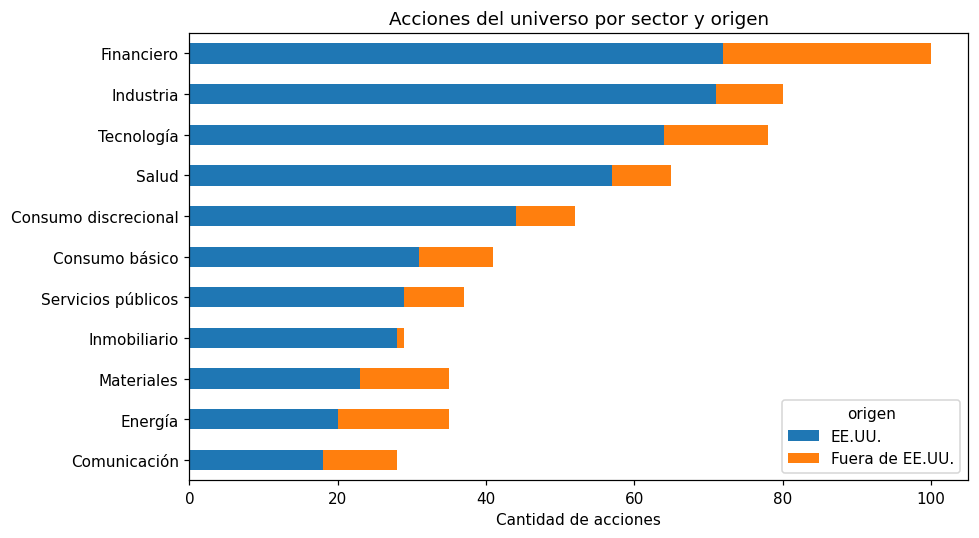

In [27]:
ax = (pd.crosstab(datos.universo["sector"], datos.universo["origen"])
        .sort_values("EE.UU.")
        .plot(kind="barh", stacked=True, figsize=(9, 5), color=["tab:blue", "tab:orange"]))
ax.set_title("Acciones del universo por sector y origen")
ax.set_xlabel("Cantidad de acciones")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

In [28]:
print(f"Acciones descartadas: {len(datos.descartados)}")
datos.descartados.sort_values("motivo")

Acciones descartadas: 50


,motivo,nombre,sector,origen
GDDY,cotiza recién desde 2015-03-31,GoDaddy,Tecnología,EE.UU.
KHC,cotiza recién desde 2015-07-06,Kraft Heinz,Consumo básico,EE.UU.
PYPL,cotiza recién desde 2015-07-06,PayPal,Financiero,EE.UU.
LITE,cotiza recién desde 2015-07-23,Lumentum,Tecnología,EE.UU.
P,cotiza recién desde 2015-10-06,Everpure,Tecnología,EE.UU.
HPE,cotiza recién desde 2015-10-19,Hewlett Packard Enterprise,Tecnología,EE.UU.
XYZ,cotiza recién desde 2015-11-19,"Block, Inc.",Financiero,EE.UU.
TWLO,cotiza recién desde 2016-06-23,Twilio,Tecnología,EE.UU.
FTV,cotiza recién desde 2016-07-05,Fortive,Industria,EE.UU.
DELL,cotiza recién desde 2016-08-17,Dell Technologies,Tecnología,EE.UU.


## 4. Señal del dólar
Medimos la fortaleza del dólar con el **índice DXY**, que compara el dólar contra una canasta de monedas (euro, yen, libra, etc.).

**Regla:** el dólar está **fuerte** si el DXY está por encima de su promedio móvil de 200 días, y **débil** si está por debajo. El promedio se calcula con `rolling(...).mean()` (Clase 6).

**Para no hacer trampa:** cada día usamos la señal **del día anterior** (`shift(1)`), porque al abrir el mercado todavía no sabemos cómo va a cerrar el dólar ese día.

In [29]:
class SenalDolar:
    """Clasifica cada día como dólar 'fuerte' o 'débil'.

    Regla: fuerte si el DXY está por encima de su promedio móvil de `ventana` días.
    Se usa la señal del día anterior (shift(1)) para no usar información del futuro.
    """

    def __init__(self, dolar, ventana):
        self.dolar = dolar.dropna()
        self.ventana = ventana
        self.promedio = None
        self.regimen = None

    def calcular(self):
        self.promedio = self.dolar.rolling(self.ventana).mean()
        fuerte = self.dolar > self.promedio
        regimen = pd.Series(np.where(fuerte, "fuerte", "débil"), index=self.dolar.index)
        regimen = regimen[self.promedio.notna()]      # los primeros días todavía no tienen promedio
        self.regimen = regimen.shift(1).dropna()      # señal de ayer
        return self

    def alinear(self, fechas):
        """Lleva la señal a las fechas de las acciones (el DXY tiene otro calendario).
        Para cada fecha toma la última señal conocida."""
        return self.regimen.reindex(fechas, method="ffill").dropna()

    def resumen(self, fechas, corte):
        """Días de cada escenario, separando el período de estimación y el de prueba."""
        reg = self.alinear(fechas)
        periodo = np.where(reg.index <= pd.Timestamp(corte), "Estimación (hasta el corte)", "Prueba (después del corte)")
        tabla = pd.crosstab(reg, periodo, margins=True, margins_name="Total")
        tabla.index.name = "Dólar"
        tabla.columns.name = "Período"
        return tabla

    def cambios_por_anio(self, fechas):
        """Cuántas veces por año cambia de escenario (para saber si la señal es estable)."""
        reg = self.alinear(fechas)
        cambios = (reg != reg.shift(1)).iloc[1:]
        return cambios.groupby(cambios.index.year).sum()

    def graficar(self, desde):
        dxy = self.dolar.loc[desde:]
        prom = self.promedio.loc[desde:]
        fuerte = (self.regimen.loc[desde:] == "fuerte")
        fig, ax = plt.subplots(figsize=(12, 4))
        ax.plot(dxy.index, dxy, lw=1, color="black", label="DXY")
        ax.plot(prom.index, prom, lw=1.5, color="tab:red", label=f"Promedio {self.ventana} días")
        ax.fill_between(fuerte.index, 0, 1, where=fuerte.values, transform=ax.get_xaxis_transform(),
                        color="tab:green", alpha=0.15, label="Dólar fuerte")
        ax.set_title("Índice del dólar (DXY) y escenarios")
        ax.legend(loc="upper left")
        plt.tight_layout()
        plt.show()

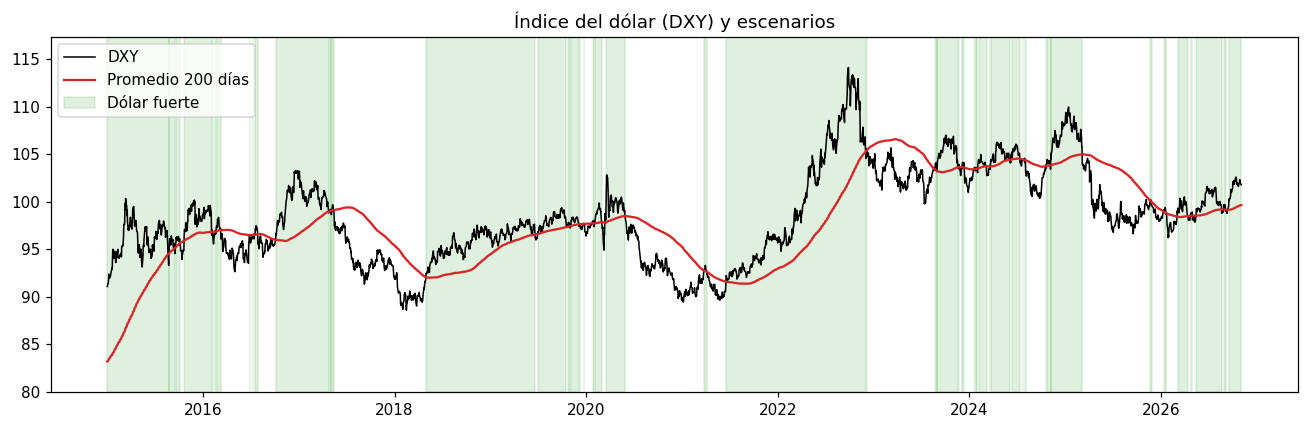

Período,Estimación (hasta el corte),Prueba (después del corte),Total
Dólar,,,
débil,732,550,1282
fuerte,1282,412,1694
Total,2014,962,2976


In [30]:
senal = SenalDolar(datos.dolar, CONFIG["ventana_dolar"]).calcular()
senal.graficar(desde=CONFIG["fecha_inicio"])
senal.resumen(datos.precios.index, CONFIG["corte"])

**Cuántas veces por año cambia el escenario.** Si cambiara todos los días, la señal sería ruido y la estrategia dinámica rotaría demasiado.

In [31]:
senal.cambios_por_anio(datos.precios.index).to_frame("cambios de escenario")

,cambios de escenario
Date,
2015,6
2016,16
2017,7
2018,1
2019,11
2020,6
2021,3
2022,3
2023,12


## 5. Primera mirada: retornos por sector según el dólar
Antes de optimizar, miramos si el dólar **cambia algo**: retorno promedio anual de las acciones de cada sector en días de dólar fuerte y débil.

- Solo usamos el **período de estimación** (hasta el corte), para no mirar los datos que después vamos a usar de prueba.
- Retorno anual = promedio de retornos diarios × 252 (Clase 7). Dentro de cada sector, todas las acciones pesan igual.
- Si la columna `diferencia` es grande, el dólar importa para ese sector.

In [32]:
retornos = datos.retornos()
reg = senal.alinear(retornos.index)
ret_est = retornos.loc[reg.index].loc[:CONFIG["corte"]]     # período de estimación con señal
reg_est = reg.loc[ret_est.index]

# Retorno medio anual de cada acción en cada escenario (filas: escenario, columnas: acciones)
media_por_escenario = ret_est.groupby(reg_est).mean() * 252

# Promedio por sector y por origen
por_sector = media_por_escenario.T.groupby(datos.universo["sector"]).mean()
por_sector["diferencia"] = por_sector["fuerte"] - por_sector["débil"]
por_origen = media_por_escenario.T.groupby(datos.universo["origen"]).mean()
por_origen["diferencia"] = por_origen["fuerte"] - por_origen["débil"]

print("Retorno medio anual por origen")
display(por_origen[["fuerte", "débil", "diferencia"]].style.format("{:.1%}"))
print("Retorno medio anual por sector")
display(por_sector[["fuerte", "débil", "diferencia"]].sort_values("diferencia").style.format("{:.1%}"))

Retorno medio anual por origen


,fuerte,débil,diferencia
origen,,,
EE.UU.,12.7%,21.4%,-8.6%
Fuera de EE.UU.,6.1%,21.7%,-15.7%


Retorno medio anual por sector


,fuerte,débil,diferencia
sector,,,
Materiales,10.6%,30.5%,-19.9%
Comunicación,4.6%,20.8%,-16.2%
Tecnología,15.4%,30.3%,-14.9%
Financiero,7.4%,22.3%,-14.9%
Industria,11.2%,23.9%,-12.7%
Energía,11.5%,23.0%,-11.5%
Inmobiliario,7.5%,16.0%,-8.5%
Consumo discrecional,14.0%,21.2%,-7.2%
Salud,14.8%,16.3%,-1.5%


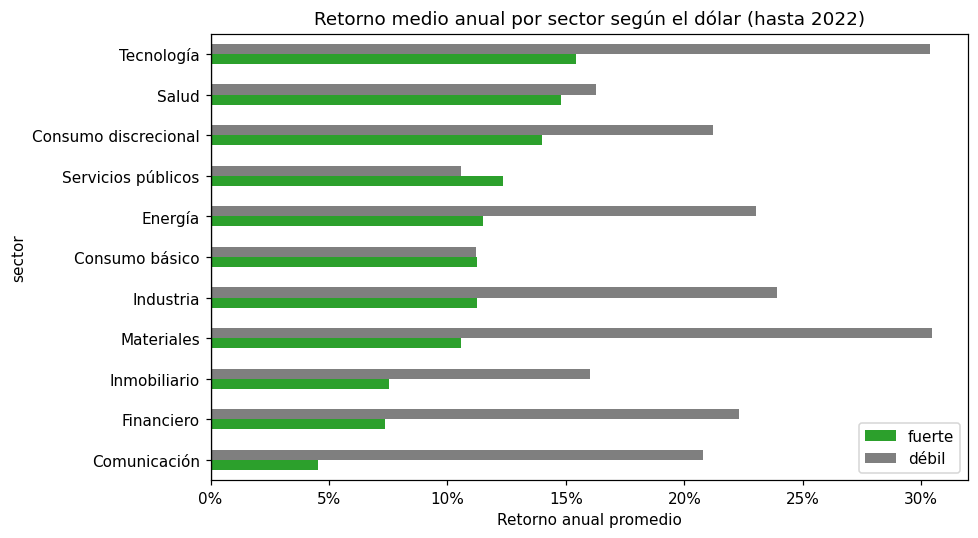

In [33]:
ax = por_sector[["fuerte", "débil"]].sort_values("fuerte").plot(
    kind="barh", figsize=(9, 5), color=["tab:green", "tab:gray"])
ax.set_title(f"Retorno medio anual por sector según el dólar (hasta {CONFIG['corte'][:4]})")
ax.set_xlabel("Retorno anual promedio")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.axvline(0, color="black", lw=0.8)
plt.tight_layout()
plt.show()

## 6. Indicadores anticipatorios: tasa a 2 años y M2
La señal de la sección 4 es **reactiva**: avisa que el dólar está fuerte cuando ya se fortaleció. Ahora buscamos indicadores que se muevan **antes** que el dólar, para anticipar si el mes que viene se va a fortalecer o debilitar.

| Indicador | Código en FRED | Qué mide | Lógica |
|---|---|---|---|
| **Tasa a 2 años** | `DGS2` | Rendimiento del bono del Tesoro a 2 años: lo que el mercado espera que haga la Fed | Si sube, la plata va a EE.UU. a buscar tasa → **dólar fuerte** |
| **M2** | `M2SL` | Cantidad de dinero de la economía de EE.UU. (emisión) | Si crece más de lo normal, hay más dólares → **dólar débil** |

**De dónde salen:** FRED, la base de datos de la Reserva Federal de St. Louis. Se leen con `pd.read_csv(url)`, igual que el CPI en la Clase 7.

**Todo pasa a frecuencia mensual:** el pronóstico se hace a fin de cada mes, para el mes siguiente. La tasa es diaria (tomamos el último valor del mes con `resample("ME").last()`, Clase 6) y el M2 ya es mensual.

**Para no usar información del futuro:** el M2 de un mes se publica unas 4 semanas después. Por eso, a fin de cada mes usamos el M2 **del mes anterior** (`CONFIG["atrasos"]`). La tasa se conoce el mismo día, no tiene atraso.

In [ ]:
class IndicadoresMacro:
    """Baja de FRED los indicadores anticipatorios del dólar y los deja en frecuencia mensual.

    Indicadores (definidos en CONFIG["indicadores"]):
        tasa_2a : rendimiento del bono del Tesoro de EE.UU. a 2 años (DGS2, diario, en %)
        m2      : cantidad de dinero M2 de EE.UU. (M2SL, mensual, en miles de millones de USD)

    Después de llamar a preparar() queda disponible:
        mensual : DataFrame con el valor de cada indicador a fin de cada mes
    """

    URL_FRED = "https://fred.stlouisfed.org/graph/fredgraph.csv?id="
    ARCHIVO = "indicadores.csv"

    def __init__(self, config):
        self.config = config
        self.mensual = None
        self.recien_bajados = False     # True si en esta corrida se bajaron de FRED

    def _bajar_serie(self, codigo):
        """Baja una serie de FRED (como el CPI de la Clase 7)."""
        url = self.URL_FRED + codigo
        try:
            serie = pd.read_csv(url, index_col=0, parse_dates=True).iloc[:, 0]
        except Exception:
            # Si FRED rechaza el pedido directo, lo pedimos identificándonos como navegador
            texto = requests.get(url, headers={"User-Agent": "Mozilla/5.0"}, timeout=30).text
            serie = pd.read_csv(io.StringIO(texto), index_col=0, parse_dates=True).iloc[:, 0]
        return pd.to_numeric(serie, errors="coerce")    # los días sin dato pasan a NaN

    def descargar(self):
        # Desde 2 años antes del inicio: para medir cambios y promedios ya en enero de 2015
        inicio = pd.Timestamp(self.config["fecha_inicio"]) - pd.DateOffset(years=2)
        columnas = {}
        for nombre, codigo in self.config["indicadores"].items():
            print(f"Bajando {nombre} ({codigo}) de FRED...")
            serie = self._bajar_serie(codigo).loc[inicio:]
            columnas[nombre] = serie.resample("ME").last()      # último valor de cada mes
        self.mensual = pd.DataFrame(columnas)
        self.recien_bajados = True
        return self

    def guardar(self):
        os.makedirs(self.config["carpeta_datos"], exist_ok=True)
        ruta = os.path.join(self.config["carpeta_datos"], self.ARCHIVO)
        self.mensual.round(4).to_csv(ruta)
        print(f"Indicadores guardados en '{ruta}'")
        return self

    def _ubicacion(self):
        """Si el archivo está en la carpeta local lo usa; si no, lo lee del repositorio en GitHub."""
        local = os.path.join(self.config["carpeta_datos"], self.ARCHIVO)
        if os.path.exists(local):
            return local
        return self.config["url_repo"] + self.config["carpeta_datos"] + "/" + self.ARCHIVO

    def cargar(self):
        self.mensual = pd.read_csv(self._ubicacion(), index_col=0, parse_dates=True)
        return self

    def preparar(self):
        if self.config["descargar_indicadores"]:
            self.descargar().guardar()
        else:
            try:
                self.cargar()
            except Exception:
                print("No hay indicadores guardados en el repositorio todavía: se bajan de FRED.")
                self.descargar().guardar()
        print(f"Indicadores listos: {list(self.mensual.columns)}, "
              f"de {self.mensual.index[0]:%m/%Y} a {self.mensual.index[-1]:%m/%Y}")
        return self

    def disponibles(self):
        """Lo que se conocía a fin de cada mes: cada indicador se corre según su atraso de publicación."""
        datos = self.mensual.copy()
        for nombre, atraso in self.config["atrasos"].items():
            datos[nombre] = datos[nombre].shift(atraso)
        return datos

In [ ]:
indicadores = IndicadoresMacro(CONFIG).preparar()
indicadores.disponibles().tail(6)

**Solo si se bajaron indicadores nuevos de FRED:** la celda siguiente baja el archivo `indicadores.csv` a la computadora, para subirlo a la carpeta `data/` del repositorio. Si se usaron los guardados, no hace nada.

In [ ]:
if indicadores.recien_bajados:
    ruta = os.path.join(CONFIG["carpeta_datos"], IndicadoresMacro.ARCHIVO)
    try:
        from google.colab import files          # solo existe dentro de Colab
        files.download(ruta)
        print("Se descargó indicadores.csv: subirlo a la carpeta data/ del repositorio.")
    except ImportError:
        print(f"No estamos en Colab: el archivo quedó en {ruta}")
else:
    print("Usando indicadores guardados: no hay nada para bajar.")

**Cómo se movieron los indicadores desde 2015.** La tasa a 2 años muestra los ciclos de la Fed (subas de 2016–2018, baja a casi 0% en 2020 y suba fuerte de 2022). El M2 muestra la emisión: el salto de 2020 es la respuesta al Covid.

In [ ]:
desde = CONFIG["fecha_inicio"]
fig, ejes = plt.subplots(1, 2, figsize=(12, 3.8))
indicadores.mensual.loc[desde:, "tasa_2a"].plot(ax=ejes[0], color="tab:blue")
ejes[0].set_title("Tasa del Tesoro a 2 años (%)")
(indicadores.mensual.loc[desde:, "m2"] / 1000).plot(ax=ejes[1], color="tab:purple")
ejes[1].set_title("M2 (billones de USD)")
for eje in ejes:
    eje.set_xlabel("")
plt.tight_layout()
plt.show()

## 7. Pronóstico del dólar
Con los dos indicadores armamos **un solo número** que pronostica qué va a hacer el dólar el mes siguiente: el **índice compuesto**.

A fin de cada mes:
1. **Cambio de cada indicador** en los últimos 3 meses (`CONFIG["ventana_indicadores"]`): la tasa en puntos (si pasó de 4,0% a 4,5%, subió 0,5) y el M2 en % de crecimiento.
2. **Escala común:** `(cambio − promedio) / desvío`, con el promedio y el desvío de 2015–2022. Así los dos quedan en "cuántos desvíos se aleja de lo normal" y se pueden sumar, aunque uno esté en puntos y el otro en %.
3. **Signo de la teoría** (`CONFIG["signos"]`): la tasa queda igual (si sube, dólar fuerte) y el M2 se multiplica por −1 (si crece de más, dólar débil). Así, en los dos, **positivo = empuja al dólar a fortalecerse**.
4. **Índice compuesto** = promedio de los dos.
5. **Pronóstico:** índice positivo → dólar **fuerte** el mes siguiente; negativo → **débil**.
6. **Regla de confirmación:** si el pronóstico coincide con la **tendencia del DXY** (por encima o por debajo de su promedio de 200 días, sección 4), se usa ese escenario; si no coinciden, la decisión es **neutral** (más adelante, la cartera que no mira el dólar).

**Para no hacer trampa:** el promedio y el desvío de la escala común salen solo de 2015–2022, y el M2 se usa con su atraso de publicación. Lo que pasa después de 2022 se usa solo para probar.

In [ ]:
class PronosticoDolar:
    """Pronóstico mensual del dólar a partir de los indicadores anticipatorios (sección 6).

    Después de llamar a calcular() quedan disponibles (una fila por fin de mes):
        puntajes   : cambio de cada indicador en escala común y con el signo de la teoría
        indice     : índice compuesto (promedio de los puntajes)
        pronostico : 'fuerte' o 'débil' para el mes siguiente, según el signo del índice
        tendencia  : 'fuerte' o 'débil' según el DXY y su promedio de 200 días (sección 4)
        decision   : el pronóstico si coincide con la tendencia; si no, 'neutral'
        real       : lo que hizo de verdad el dólar el mes siguiente
    """

    NOMBRES = {"tasa_2a": "Tasa a 2 años", "m2": "M2"}

    def __init__(self, indicadores, senal, config, ventana=None):
        self.indicadores = indicadores
        self.senal = senal
        self.config = config
        self.ventana = ventana if ventana is not None else config["ventana_indicadores"]
        self.inicio = pd.Timestamp(config["fecha_inicio"])
        self.corte = pd.Timestamp(config["corte"])
        # DXY a fin de cada mes. Si el último mes todavía no terminó, se saca (su cambio estaría incompleto)
        dxy = senal.dolar.resample("ME").last()
        if senal.dolar.index[-1] < dxy.index[-1] - pd.Timedelta(days=3):
            dxy = dxy.iloc[:-1]
        self.dxy = dxy

    @staticmethod
    def _a_escenario(serie):
        """Positivo -> 'fuerte', negativo -> 'débil', sin dato -> NaN."""
        return pd.Series(np.where(serie > 0, "fuerte", "débil"), index=serie.index).where(serie.notna())

    @staticmethod
    def _etiqueta(meses):
        return "1 mes" if meses == 1 else f"{meses} meses"

    def _cambios(self):
        """Cambio de cada indicador en los últimos `ventana` meses."""
        # Último dato publicado: si el M2 del último mes todavía no salió, se repite el anterior
        datos = self.indicadores.disponibles().ffill()
        cambios = pd.DataFrame(index=datos.index)
        for nombre, medicion in self.config["medicion"].items():
            anterior = datos[nombre].shift(self.ventana)
            if medicion == "puntos":
                cambios[nombre] = datos[nombre] - anterior          # tasa: cuántos puntos subió o bajó
            else:
                cambios[nombre] = datos[nombre] / anterior - 1      # M2: cuánto % creció
        return cambios.loc[self.inicio:]

    def cambio_futuro(self, meses):
        """Cambio % del DXY en los `meses` siguientes a cada fin de mes."""
        return (self.dxy.shift(-meses) / self.dxy - 1).reindex(self.indice.index)

    def calcular(self):
        cambios = self._cambios()
        estimacion = cambios.loc[:self.corte]
        # Escala común con el promedio y el desvío de 2015–2022 (broadcasting por columna, Clase 5)
        z = (cambios - estimacion.mean()) / estimacion.std()
        self.puntajes = z * pd.Series(self.config["signos"])       # positivo = dólar fuerte
        self.indice = self.puntajes.mean(axis=1)

        self.pronostico = self._a_escenario(self.indice)
        # Tendencia del DXY a fin de mes (al cierre del último día del mes ya se conoce)
        diferencia = (self.senal.dolar - self.senal.promedio).resample("ME").last()
        self.tendencia = self._a_escenario(diferencia.reindex(self.indice.index))
        self.real = self._a_escenario(self.cambio_futuro(1))
        coinciden = self.pronostico == self.tendencia
        self.decision = self.pronostico.where(coinciden, "neutral").where(self.pronostico.notna())
        return self

    def _meses(self, periodo, horizonte):
        """Meses de 'estimación' (el resultado se conoce antes del corte) o de 'prueba' (después del corte)."""
        fechas = self.indice.index
        if periodo == "estimación":
            return fechas[fechas <= self.corte - pd.offsets.MonthEnd(horizonte)]
        return fechas[fechas > self.corte]

    def tabla(self):
        """Todo junto, mes por mes."""
        return pd.DataFrame({"índice": self.indice, "pronóstico": self.pronostico,
                             "tendencia DXY": self.tendencia, "decisión": self.decision,
                             "lo que pasó": self.real})

    def correlaciones(self):
        """Correlación entre cada señal de hoy y el cambio del DXY en los meses siguientes (2015–2022)."""
        senales = self.puntajes.rename(columns=self.NOMBRES)
        senales["Índice combinado"] = self.indice
        tabla = {}
        for h in self.config["horizontes"]:
            meses = self._meses("estimación", h)
            tabla[self._etiqueta(h)] = senales.loc[meses].corrwith(self.cambio_futuro(h).loc[meses])
        return pd.DataFrame(tabla)

    def aciertos(self, periodo):
        """% de meses en que cada señal acertó si el dólar iba a subir o bajar, para cada horizonte."""
        senales = {self.NOMBRES[c]: self._a_escenario(self.puntajes[c]) for c in self.puntajes.columns}
        senales["Índice combinado"] = self.pronostico
        senales["Tendencia del DXY (200 días)"] = self.tendencia
        tabla = {}
        for h in self.config["horizontes"]:
            meses = self._meses(periodo, h)
            real = self._a_escenario(self.cambio_futuro(h)).loc[meses].dropna()
            fila = {nombre: (s.reindex(real.index) == real).mean() for nombre, s in senales.items()}
            fila["Decir siempre 'fuerte'"] = (real == "fuerte").mean()
            fila["Azar"] = 0.5
            tabla[self._etiqueta(h)] = pd.Series(fila)
        return pd.DataFrame(tabla)

    def sensibilidad(self):
        """Aciertos del índice combinado (a 1 mes) midiendo el cambio con distintas ventanas."""
        filas = {}
        for v in self.config["ventanas_sensibilidad"]:
            otro = PronosticoDolar(self.indicadores, self.senal, self.config, ventana=v).calcular()
            filas[f"Ventana de {self._etiqueta(v)}"] = {
                "Estimación (2015–2022)": otro.aciertos("estimación").loc["Índice combinado", "1 mes"],
                "Prueba (2023 en adelante)": otro.aciertos("prueba").loc["Índice combinado", "1 mes"],
            }
        return pd.DataFrame(filas).T

    def resumen_decisiones(self):
        """Cuántos meses la regla de confirmación eligió cada escenario y cuánto acertó cuando no fue neutral."""
        filas = {}
        for periodo, nombre in [("estimación", "Estimación (2015–2022)"), ("prueba", "Prueba (2023 en adelante)")]:
            meses = self._meses(periodo, 1)
            decision, real = self.decision.loc[meses], self.real.loc[meses]
            toma_posicion = decision.isin(["fuerte", "débil"]) & real.notna()
            filas[nombre] = {
                "meses 'fuerte'": int((decision == "fuerte").sum()),
                "meses 'débil'": int((decision == "débil").sum()),
                "meses 'neutral'": int((decision == "neutral").sum()),
                "aciertos cuando no es neutral": (decision[toma_posicion] == real[toma_posicion]).mean(),
            }
        return pd.DataFrame(filas).T

    def graficar_base1(self):
        """DXY y M2 en base 1 (arrancan en 1) y la tasa en su propio eje."""
        dxy = self.dxy.loc[self.inicio:]
        m2 = self.indicadores.mensual["m2"].loc[self.inicio:].dropna()
        tasa = self.indicadores.mensual["tasa_2a"].loc[self.inicio:]
        fig, ax = plt.subplots(figsize=(12, 4))
        ax.plot(dxy.index, dxy / dxy.iloc[0], color="black", label="DXY (base 1)")
        ax.plot(m2.index, m2 / m2.iloc[0], color="tab:purple", label="M2 (base 1)")
        ax.set_ylabel("Base 1 = enero 2015")
        ax2 = ax.twinx()
        ax2.plot(tasa.index, tasa, color="tab:blue", alpha=0.6, label="Tasa a 2 años (%, eje derecho)")
        ax2.set_ylabel("Tasa (%)")
        lineas = ax.get_lines() + ax2.get_lines()
        ax.legend(lineas, [l.get_label() for l in lineas], loc="upper left")
        ax.set_title("Dólar, emisión y tasas")
        plt.tight_layout()
        plt.show()

    def graficar_indice(self):
        """Índice compuesto mes a mes: verde = pronostica dólar fuerte, gris = débil."""
        indice = self.indice.dropna()
        colores = np.where(indice > 0, "tab:green", "tab:gray")
        fig, ax = plt.subplots(figsize=(12, 3.5))
        ax.bar(indice.index, indice.values, width=25, color=colores)
        ax.axhline(0, color="black", lw=0.8)
        ax.axvline(self.corte, color="tab:red", ls="--", lw=1, label="Corte: estimación | prueba")
        ax.set_title("Índice compuesto (positivo = pronostica dólar fuerte el mes siguiente)")
        ax.legend(loc="upper left")
        plt.tight_layout()
        plt.show()

In [ ]:
pronostico = PronosticoDolar(indicadores, senal, CONFIG).calcular()
pronostico.graficar_base1()
pronostico.graficar_indice()

### ¿Los indicadores se adelantan al dólar?
**Correlación** entre cada señal a fin de mes y lo que hace el DXY en los 1, 3 y 6 meses siguientes, con datos de 2015–2022. Como los puntajes ya tienen el signo de la teoría, **si la teoría se cumple la correlación tiene que ser positiva**: cuanto más alta, más se adelanta la señal al dólar.

Cuidado al leer las columnas de 3 y 6 meses: cada mes comparte casi todo su período con el siguiente (la ventana se superpone), así que hay menos información independiente de la que parece y las correlaciones tienden a verse más altas.

In [ ]:
pronostico.correlaciones().style.format("{:+.2f}").background_gradient(cmap="RdYlGn", vmin=-0.5, vmax=0.5)

### ¿Cuánto acierta cada señal?
**% de meses en que acertó** si el dólar iba a subir o bajar en los 1, 3 y 6 meses siguientes. Hay dos referencias para comparar:
- **Azar:** 50%. Una señal que no supera eso no sirve.
- **Decir siempre "fuerte":** como el dólar subió en más de la mitad de los meses, apostar siempre a que sube ya acierta más que 50%. Una señal útil tiene que superar también esto.

Las decisiones (qué indicadores usar, qué ventana) se toman **solo con la tabla de 2015–2022**. La de 2023 en adelante es la prueba: muestra si lo que funcionó antes siguió funcionando.

In [ ]:
print("Aciertos en el período de estimación (2015–2022)")
display(pronostico.aciertos("estimación").style.format("{:.0%}"))
print("Aciertos en el período de prueba (2023 en adelante)")
display(pronostico.aciertos("prueba").style.format("{:.0%}"))

### Sensibilidad a la ventana
El cambio de los indicadores se mide en 3 meses, pero es un supuesto. Acá se recalcula todo midiendo el cambio en 1, 3 y 6 meses (`CONFIG["ventanas_sensibilidad"]`), para ver si el resultado depende mucho de esa elección. La ventana se elige con la columna de estimación.

In [ ]:
pronostico.sensibilidad().style.format("{:.0%}")

### Regla de confirmación
Cuántos meses la regla eligió dólar fuerte, débil o neutral (cuando el índice y la tendencia del DXY no coinciden), y qué porcentaje acertó en los meses en que tomó posición.

In [ ]:
pronostico.resumen_decisiones().style.format("{:.0f}").format("{:.0%}", subset=["aciertos cuando no es neutral"])

**Los últimos meses, uno por uno.** La última fila es la lectura más reciente: lo que el índice pronostica para el mes que viene (la columna "lo que pasó" todavía no se conoce).

In [ ]:
pronostico.tabla().tail(8)

## 8. Próximas secciones (en construcción)
- **8. Escenarios**: meses de suba y de baja del dólar; retornos por sector en cada uno.
- **9. Estimación de μ y Σ** por escenario, vectorizada y con Ledoit-Wolf.
- **10. Optimizador y carteras**: 3 perfiles × 3 escenarios.
- **11. Recomendación de hoy**: escenario esperado para el mes que viene y cartera para cada perfil.
- **12. Backtest y métricas** fuera de muestra (2023–2026).
- **13. Stress test** y **14. Conclusiones**.